In [ ]:

# ==================================================
# 01. CONFIGURACIÓN DEL ENTORNO
# Reanudación del Transformer: época 15/15
# ==================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import json
import random
import numpy as np
import torch
import sentencepiece as spm

from pathlib import Path

# Directorio del proyecto
BASE_DIR = Path(
    "/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado"
)

DATA_DIR = BASE_DIR / "datasets" / "raw"
MODEL_DIR = BASE_DIR / "modelo"
CONFIG_DIR = BASE_DIR / "configuracion"
TOKENIZER_DIR = BASE_DIR / "tokenizador"
CHECKPOINT_DIR = BASE_DIR / "checkpoints"
RESULTS_DIR = BASE_DIR / "resultados"

LAST_CHECKPOINT = CHECKPOINT_DIR / "ultimo_checkpoint.pth"
BEST_CHECKPOINT = CHECKPOINT_DIR / "mejor_modelo.pth"

# Verificar archivos antes de continuar
archivos = [
    DATA_DIR / "train.tsv",
    DATA_DIR / "val.tsv",
    MODEL_DIR / "transformer_model.py",
    CONFIG_DIR / "modelo_config.json",
    TOKENIZER_DIR / "tokenizer.model",
    LAST_CHECKPOINT,
    BEST_CHECKPOINT
]

for archivo in archivos:
    assert archivo.is_file(), f"Archivo faltante: {archivo}"

# GPU
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", "Activa la GPU T4 en Colab."

# Cargar configuraciones
with open(CONFIG_DIR / "modelo_config.json", encoding="utf-8") as f:
    MODEL_CONFIG = json.load(f)

# Cargar checkpoint sin modificarlo
checkpoint = torch.load(
    LAST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

TRAIN_CONFIG = checkpoint["train_config"].copy()

# Verificar continuidad
assert checkpoint["epoch"] == 13
assert len(checkpoint["history"]["epoch"]) == 14
assert TRAIN_CONFIG["epochs"] == 15
assert checkpoint["model_config"] == MODEL_CONFIG

print("=" * 60)
print("ENTORNO DE REANUDACIÓN")
print("=" * 60)
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Épocas completadas:", checkpoint["epoch"] + 1)
print("Época pendiente:", 15)
print("Mejor Validation Loss:", checkpoint["best_val_loss"])
print("Archivos originales: OK")
print("Checkpoint: OK")
print("\nEntorno preparado correctamente.")


Mounted at /content/drive
ENTORNO DE REANUDACIÓN
GPU: Tesla T4
PyTorch: 2.11.0+cu130
Épocas completadas: 14
Época pendiente: 15
Mejor Validation Loss: 2.038661560709942
Archivos originales: OK
Checkpoint: OK

Entorno preparado correctamente.


In [ ]:

# ==================================================
# 02. TOKENIZADOR, DATASET Y DATALOADERS
# ==================================================

import csv
import pandas as pd
import sentencepiece as spm

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# 1. Cargar tokenizador original
sp = spm.SentencePieceProcessor()

assert sp.load(str(TOKENIZER_DIR / "tokenizer.model"))

assert sp.vocab_size() == 16000
assert sp.pad_id() == 0
assert sp.bos_id() == 2
assert sp.eos_id() == 3

print("Tokenizador BPE cargado:", sp.vocab_size(), "tokens")


# 2. Cargar datasets originales
def cargar_tsv(ruta):
    return pd.read_csv(
        ruta,
        sep="\t",
        header=None,
        names=["en", "es", "id_original"],
        dtype=str,
        keep_default_na=False,
        quoting=csv.QUOTE_NONE
    )

train_df = cargar_tsv(DATA_DIR / "train.tsv")
val_df = cargar_tsv(DATA_DIR / "val.tsv")

assert len(train_df) == 792070
assert len(val_df) == 44004


# 3. Dataset original
class TranslationDataset(Dataset):

    def __init__(self, df, tokenizer, max_length=80):
        self.en = df["en"].tolist()
        self.es = df["es"].tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.en)

    def encode(self, text):
        tokens = self.tokenizer.encode(text, out_type=int)
        tokens = tokens[:self.max_length - 2]

        return (
            [self.tokenizer.bos_id()]
            + tokens
            + [self.tokenizer.eos_id()]
        )

    def __getitem__(self, idx):
        src = self.encode(self.en[idx])
        tgt = self.encode(self.es[idx])

        return (
            torch.tensor(src, dtype=torch.long),
            torch.tensor(tgt, dtype=torch.long)
        )


# 4. Padding dinámico original
def collate_fn(batch):
    src_list, tgt_list = zip(*batch)

    src = pad_sequence(
        src_list,
        batch_first=True,
        padding_value=sp.pad_id()
    )

    tgt = pad_sequence(
        tgt_list,
        batch_first=True,
        padding_value=sp.pad_id()
    )

    return src, tgt[:, :-1], tgt[:, 1:]


# 5. Crear datasets
train_dataset = TranslationDataset(
    train_df, sp, MODEL_CONFIG["max_length"]
)

val_dataset = TranslationDataset(
    val_df, sp, MODEL_CONFIG["max_length"]
)


# 6. Crear DataLoaders
BATCH_SIZE = TRAIN_CONFIG["batch_size"]

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)


# 7. Verificaciones
src, tgt_input, tgt_expected = next(iter(train_loader))

assert tgt_input.shape == tgt_expected.shape
assert src.shape[0] == BATCH_SIZE

assert len(train_loader) == 24753
assert len(val_loader) == 1376

print("\n" + "=" * 60)
print("DATASETS Y DATALOADERS VERIFICADOS")
print("=" * 60)

print(f"Train: {len(train_dataset):,} ejemplos")
print(f"Validation: {len(val_dataset):,} ejemplos")
print("Batch size:", BATCH_SIZE)
print("Lotes entrenamiento:", len(train_loader))
print("Lotes validación:", len(val_loader))
print("Encoder:", tuple(src.shape))
print("Decoder input:", tuple(tgt_input.shape))
print("Decoder target:", tuple(tgt_expected.shape))

print("\nCelda 2 completada correctamente.")


Tokenizador BPE cargado: 16000 tokens

DATASETS Y DATALOADERS VERIFICADOS
Train: 792,070 ejemplos
Validation: 44,004 ejemplos
Batch size: 32
Lotes entrenamiento: 24753
Lotes validación: 1376
Encoder: (32, 20)
Decoder input: (32, 20)
Decoder target: (32, 20)

Celda 2 completada correctamente.


In [ ]:

# ==================================================
# 03. RESTAURACIÓN DEL TRANSFORMER
# ==================================================

import sys
import torch

# 1. Importar arquitectura original
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

from transformer_model import TranslationTransformer

# 2. Verificar configuración
assert MODEL_CONFIG == checkpoint["model_config"]

# 3. Reconstruir arquitectura
model = TranslationTransformer(
    MODEL_CONFIG
).to(DEVICE)

# 4. Recuperar pesos de las 14 épocas
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

# 5. Mantener modo evaluación hasta iniciar entrenamiento
model.eval()

# 6. Verificar parámetros
total_params = sum(
    p.numel() for p in model.parameters()
)

assert total_params == 19677824

print("=" * 60)
print("TRANSFORMER RESTAURADO")
print("=" * 60)
print("Arquitectura: Encoder-Decoder Transformer")
print("Parámetros:", f"{total_params:,}")
print("Dispositivo:", DEVICE)
print("Épocas completadas:", checkpoint["epoch"] + 1)
print("Pesos originales: OK")
print("\nCelda 3 completada correctamente.")


TRANSFORMER RESTAURADO
Arquitectura: Encoder-Decoder Transformer
Parámetros: 19,677,824
Dispositivo: cuda
Épocas completadas: 14
Pesos originales: OK

Celda 3 completada correctamente.


In [ ]:

# ==================================================
# 04. RECUPERACIÓN DE ESTADOS DE ENTRENAMIENTO
# ==================================================

import torch
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR

# 1. Configuración original del checkpoint
TRAIN_CONFIG = checkpoint["train_config"].copy()

total_steps = TRAIN_CONFIG["total_steps"]
warmup_steps = TRAIN_CONFIG["warmup_steps"]

# 2. Reconstruir optimizador
optimizer = AdamW(
    model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"]
)

# 3. Scheduler original: warmup + decaimiento lineal
def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps

    progress = (
        (step - warmup_steps)
        / max(1, total_steps - warmup_steps)
    )

    return max(
        TRAIN_CONFIG["min_lr_ratio"],
        1.0 - progress * (
            1.0 - TRAIN_CONFIG["min_lr_ratio"]
        )
    )

scheduler = LambdaLR(
    optimizer,
    lr_lambda=lr_lambda
)

# 4. Restaurar estados originales
optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

scheduler.load_state_dict(
    checkpoint["scheduler_state_dict"]
)

# 5. Restaurar GradScaler
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=TRAIN_CONFIG["use_amp"] and DEVICE.type == "cuda"
)

scaler.load_state_dict(
    checkpoint["scaler_state_dict"]
)

# 6. Sincronizar LR con el checkpoint
for grupo, grupo_guardado in zip(
    optimizer.param_groups,
    checkpoint["optimizer_state_dict"]["param_groups"]
):
    grupo["lr"] = grupo_guardado["lr"]

# 7. Comprobaciones
lr_optimizer = optimizer.param_groups[0]["lr"]
lr_scheduler = scheduler.get_last_lr()[0]

assert abs(lr_optimizer - lr_scheduler) < 1e-10
assert scheduler.last_epoch == 86631
assert len(optimizer.state) > 0
assert scaler.is_enabled()

print("=" * 60)
print("ESTADOS RESTAURADOS CORRECTAMENTE")
print("=" * 60)
print("Optimizador: AdamW")
print("Estados AdamW:", len(optimizer.state))
print("Learning Rate:", lr_optimizer)
print("LR Scheduler:", lr_scheduler)
print("Scheduler step:", scheduler.last_epoch)
print("GradScaler:", scaler.is_enabled())
print("Escala AMP:", scaler.get_scale())
print("Épocas completadas:", checkpoint["epoch"] + 1)
print("Siguiente época:", checkpoint["epoch"] + 2)
print("\nCelda 4 completada correctamente.")


ESTADOS RESTAURADOS CORRECTAMENTE
Optimizador: AdamW
Estados AdamW: 128
Learning Rate: 4.899312878427103e-05
LR Scheduler: 4.899312878427103e-05
Scheduler step: 86631
GradScaler: True
Escala AMP: 262144.0
Épocas completadas: 14
Siguiente época: 15

Celda 4 completada correctamente.


In [ ]:

# ==================================================
# 05. FUNCIONES DE ENTRENAMIENTO Y VALIDACIÓN
# ==================================================

import math
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

def calcular_loss(logits, targets):
    vocab_size = logits.size(-1)

    loss_sum = F.cross_entropy(
        logits.reshape(-1, vocab_size).float(),
        targets.reshape(-1),
        ignore_index=MODEL_CONFIG["pad_id"],
        reduction="sum",
        label_smoothing=TRAIN_CONFIG["label_smoothing"]
    )

    num_tokens = targets.ne(
        MODEL_CONFIG["pad_id"]
    ).sum().item()

    return loss_sum, num_tokens


def entrenar_epoca(epoch):
    model.train()

    total_loss = 0.0
    total_tokens = 0

    accumulation_steps = TRAIN_CONFIG["gradient_accumulation_steps"]
    total_batches = len(train_loader)

    optimizer.zero_grad(set_to_none=True)

    progreso = tqdm(
        train_loader,
        desc=f"Entrenamiento | Época {epoch + 1}",
        leave=True
    )

    for batch_idx, (src, tgt_input, tgt_expected) in enumerate(progreso):

        src = src.to(DEVICE, non_blocking=True)
        tgt_input = tgt_input.to(DEVICE, non_blocking=True)
        tgt_expected = tgt_expected.to(DEVICE, non_blocking=True)

        group_start = (
            batch_idx // accumulation_steps
        ) * accumulation_steps

        group_size = min(
            accumulation_steps,
            total_batches - group_start
        )

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=scaler.is_enabled()
        ):
            logits = model(src, tgt_input)

            loss_sum, num_tokens = calcular_loss(
                logits, tgt_expected
            )

            loss = (
                loss_sum / max(1, num_tokens)
            ) / group_size

        scaler.scale(loss).backward()

        total_loss += loss_sum.detach().item()
        total_tokens += num_tokens

        is_update_step = (
            (batch_idx + 1) % accumulation_steps == 0
            or (batch_idx + 1) == total_batches
        )

        if is_update_step:
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=TRAIN_CONFIG["max_grad_norm"]
            )

            previous_scale = scaler.get_scale()

            scaler.step(optimizer)
            scaler.update()

            if scaler.get_scale() >= previous_scale:
                scheduler.step()

            optimizer.zero_grad(set_to_none=True)

        if (batch_idx + 1) % 100 == 0:
            progreso.set_postfix({
                "loss": f"{total_loss / max(1, total_tokens):.4f}",
                "lr": f"{optimizer.param_groups[0]['lr']:.2e}"
            })

    return total_loss / max(1, total_tokens)


@torch.no_grad()
def validar_epoca(epoch):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    progreso = tqdm(
        val_loader,
        desc=f"Validación | Época {epoch + 1}",
        leave=False
    )

    for src, tgt_input, tgt_expected in progreso:
        src = src.to(DEVICE, non_blocking=True)
        tgt_input = tgt_input.to(DEVICE, non_blocking=True)
        tgt_expected = tgt_expected.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=scaler.is_enabled()
        ):
            logits = model(src, tgt_input)

            loss_sum, num_tokens = calcular_loss(
                logits, tgt_expected
            )

        total_loss += loss_sum.item()
        total_tokens += num_tokens

    val_loss = total_loss / max(1, total_tokens)
    val_perplexity = math.exp(min(val_loss, 100))

    return val_loss, val_perplexity


print("=" * 60)
print("FUNCIONES DE ENTRENAMIENTO Y VALIDACIÓN")
print("=" * 60)
print("entrenar_epoca(): OK")
print("validar_epoca(): OK")
print("Loss: Cross-entropy ignorando PAD")
print("Acumulación:", TRAIN_CONFIG["gradient_accumulation_steps"])
print("Gradient clipping:", TRAIN_CONFIG["max_grad_norm"])
print("AMP FP16:", scaler.is_enabled())
print("Época pendiente: 15/15")
print("\nCelda 5 completada correctamente.")


FUNCIONES DE ENTRENAMIENTO Y VALIDACIÓN
entrenar_epoca(): OK
validar_epoca(): OK
Loss: Cross-entropy ignorando PAD
Acumulación: 4
Gradient clipping: 1.0
AMP FP16: True
Época pendiente: 15/15

Celda 5 completada correctamente.


In [ ]:
# ==================================================
# 06. CHECKPOINTS, HISTORIAL Y CONTINUIDAD
# ==================================================

import json
import random
import numpy as np
import torch
from pathlib import Path

CHECKPOINT_DIR = BASE_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

LAST_CHECKPOINT = CHECKPOINT_DIR / "ultimo_checkpoint.pth"
BEST_CHECKPOINT = CHECKPOINT_DIR / "mejor_modelo.pth"
HISTORY_PATH = RESULTS_DIR / "historial_entrenamiento.json"


def guardar_checkpoint(
    ruta,
    epoch,
    model,
    optimizer,
    scheduler,
    scaler,
    best_val_loss,
    history
):
    checkpoint_guardado = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "history": history,
        "model_config": MODEL_CONFIG,
        "train_config": TRAIN_CONFIG,

        "torch_rng_state": torch.get_rng_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate()
    }

    if torch.cuda.is_available():
        checkpoint_guardado["cuda_rng_state"] = (
            torch.cuda.get_rng_state_all()
        )

    ruta = Path(ruta)
    temporal = ruta.with_suffix(".tmp")

    torch.save(checkpoint_guardado, temporal)
    temporal.replace(ruta)


def guardar_historial(history):
    temporal = HISTORY_PATH.with_suffix(".tmp")

    with open(temporal, "w", encoding="utf-8") as f:
        json.dump(
            history,
            f,
            indent=4,
            ensure_ascii=False
        )

    temporal.replace(HISTORY_PATH)


# --------------------------------------------------
# Recuperar historial y mejor loss
# --------------------------------------------------

start_epoch = checkpoint["epoch"] + 1
best_val_loss = checkpoint["best_val_loss"]
history = checkpoint["history"]

# Restaurar estados aleatorios originales
torch.set_rng_state(
    checkpoint["torch_rng_state"].cpu()
)

np.random.set_state(
    checkpoint["numpy_rng_state"]
)

random.setstate(
    checkpoint["python_rng_state"]
)

if (
    torch.cuda.is_available()
    and "cuda_rng_state" in checkpoint
):
    torch.cuda.set_rng_state_all(
        [estado.cpu() for estado in checkpoint["cuda_rng_state"]]
    )

# --------------------------------------------------
# Verificaciones
# --------------------------------------------------

assert start_epoch == 14
assert len(history["epoch"]) == 14
assert history["epoch"][-1] == 14
assert TRAIN_CONFIG["epochs"] == 15

assert abs(
    best_val_loss - 2.038661560709942
) < 1e-12

print("=" * 60)
print("CONTINUIDAD DEL ENTRENAMIENTO VERIFICADA")
print("=" * 60)

print("Épocas completadas:", len(history["epoch"]))
print("start_epoch:", start_epoch)
print("Próxima época:", start_epoch + 1)
print("Total de épocas:", TRAIN_CONFIG["epochs"])
print("Mejor Validation Loss:", best_val_loss)

print("\nÚltimo registro:")
print("Epoch:", history["epoch"][-1])
print("Train Loss:", history["train_loss"][-1])
print("Val Loss:", history["val_loss"][-1])
print("Val PPL:", history["val_perplexity"][-1])
print("LR:", history["learning_rate"][-1])

print("\nEstados RNG: restaurados")
print("Sistema de checkpoints: preparado")
print("Historial: recuperado")
print("\nCelda 6 completada correctamente.")

CONTINUIDAD DEL ENTRENAMIENTO VERIFICADA
Épocas completadas: 14
start_epoch: 14
Próxima época: 15
Total de épocas: 15
Mejor Validation Loss: 2.038661560709942

Último registro:
Epoch: 14
Train Loss: 1.9596120863831772
Val Loss: 2.038661560709942
Val PPL: 7.680322670844999
LR: 4.899312878427103e-05

Estados RNG: restaurados
Sistema de checkpoints: preparado
Historial: recuperado

Celda 6 completada correctamente.


In [ ]:
# ==================================================
# 07. VERIFICACIÓN FINAL ANTES DE ÉPOCA 15
# ==================================================

import shutil
import torch

# --------------------------------------------------
# 1. Copias de seguridad de los checkpoints actuales
# --------------------------------------------------

BACKUP_LAST = CHECKPOINT_DIR / "ultimo_checkpoint_epoca14_backup.pth"
BACKUP_BEST = CHECKPOINT_DIR / "mejor_modelo_epoca14_backup.pth"

if not BACKUP_LAST.exists():
    shutil.copy2(LAST_CHECKPOINT, BACKUP_LAST)

if not BACKUP_BEST.exists():
    shutil.copy2(BEST_CHECKPOINT, BACKUP_BEST)

# --------------------------------------------------
# 2. Verificaciones críticas
# --------------------------------------------------

assert LAST_CHECKPOINT.exists()
assert BEST_CHECKPOINT.exists()
assert BACKUP_LAST.exists()
assert BACKUP_BEST.exists()

assert start_epoch == 14
assert TRAIN_CONFIG["epochs"] == 15
assert len(history["epoch"]) == 14
assert history["epoch"][-1] == 14

assert checkpoint["epoch"] == 13

# Modelo
assert sum(p.numel() for p in model.parameters()) == 19_677_824

# Scheduler
assert scheduler.last_epoch == 86631

# Learning rate
lr_optimizer = optimizer.param_groups[0]["lr"]
lr_scheduler = scheduler.get_last_lr()[0]

assert abs(lr_optimizer - lr_scheduler) < 1e-10
assert abs(
    lr_optimizer - 4.899312878427103e-05
) < 1e-12

# AMP
assert scaler.is_enabled()
assert scaler.get_scale() == 262144.0

# DataLoaders
assert len(train_loader) == 24753
assert len(val_loader) == 1376

# --------------------------------------------------
# 3. Memoria GPU
# --------------------------------------------------

torch.cuda.empty_cache()

gpu_allocated = torch.cuda.memory_allocated() / 1024**3
gpu_reserved = torch.cuda.memory_reserved() / 1024**3

print("=" * 65)
print("VERIFICACIÓN FINAL — LISTO PARA ÉPOCA 15")
print("=" * 65)

print("Modelo:", "OK")
print("Parámetros:", f"{sum(p.numel() for p in model.parameters()):,}")
print("AdamW:", "OK")
print("Scheduler:", scheduler.last_epoch)
print("Learning Rate:", lr_optimizer)
print("GradScaler:", scaler.get_scale())

print("\nDatos:")
print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

print("\nEntrenamiento:")
print("Épocas completadas:", len(history["epoch"]))
print("Siguiente época:", start_epoch + 1)
print("Épocas totales:", TRAIN_CONFIG["epochs"])

print("\nBackups:")
print("Último checkpoint época 14:", BACKUP_LAST.name)
print("Mejor modelo época 14:", BACKUP_BEST.name)

print("\nGPU:")
print("Asignada:", f"{gpu_allocated:.2f} GB")
print("Reservada:", f"{gpu_reserved:.2f} GB")

print("\nTODO CORRECTO.")
print("Todavía NO se ha iniciado la época 15.")

VERIFICACIÓN FINAL — LISTO PARA ÉPOCA 15
Modelo: OK
Parámetros: 19,677,824
AdamW: OK
Scheduler: 86631
Learning Rate: 4.899312878427103e-05
GradScaler: 262144.0

Datos:
Train batches: 24753
Val batches: 1376

Entrenamiento:
Épocas completadas: 14
Siguiente época: 15
Épocas totales: 15

Backups:
Último checkpoint época 14: ultimo_checkpoint_epoca14_backup.pth
Mejor modelo época 14: mejor_modelo_epoca14_backup.pth

GPU:
Asignada: 0.22 GB
Reservada: 0.22 GB

TODO CORRECTO.
Todavía NO se ha iniciado la época 15.


In [ ]:
# ==================================================
# 08. ENTRENAMIENTO FINAL — ÉPOCA 15/15
# ==================================================

import time

print("=" * 65)
print("INICIANDO ÉPOCA 15/15")
print("=" * 65)

# Seguridad: debe quedar exactamente una época pendiente
assert start_epoch == 14
assert TRAIN_CONFIG["epochs"] == 15
assert list(range(start_epoch, TRAIN_CONFIG["epochs"])) == [14]

for epoch in range(start_epoch, TRAIN_CONFIG["epochs"]):

    print("\n" + "=" * 60)
    print(f"ÉPOCA {epoch + 1}/{TRAIN_CONFIG['epochs']}")
    print("=" * 60)

    inicio = time.perf_counter()

    # 1. Entrenamiento
    train_loss = entrenar_epoca(epoch)

    # 2. Validación
    val_loss, val_perplexity = validar_epoca(epoch)

    duracion = time.perf_counter() - inicio

    current_lr = optimizer.param_groups[0]["lr"]

    # 3. Registrar métricas
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(float(train_loss))
    history["val_loss"].append(float(val_loss))
    history["val_perplexity"].append(float(val_perplexity))
    history["learning_rate"].append(float(current_lr))
    history["epoch_time_seconds"].append(float(duracion))

    # 4. Comprobar mejor modelo
    es_mejor = val_loss < best_val_loss

    if es_mejor:
        best_val_loss = val_loss

    # 5. Guardar último checkpoint
    guardar_checkpoint(
        LAST_CHECKPOINT,
        epoch,
        model,
        optimizer,
        scheduler,
        scaler,
        best_val_loss,
        history
    )

    # 6. Guardar mejor modelo solo si mejora
    if es_mejor:
        guardar_checkpoint(
            BEST_CHECKPOINT,
            epoch,
            model,
            optimizer,
            scheduler,
            scaler,
            best_val_loss,
            history
        )

        print("\nNuevo mejor modelo guardado.")

    # 7. Guardar historial
    guardar_historial(history)

    # 8. Resumen
    print("\n" + "-" * 60)
    print(f"RESULTADOS ÉPOCA {epoch + 1}")
    print("-" * 60)

    print(f"Train Loss:       {train_loss:.4f}")
    print(f"Validation Loss:  {val_loss:.4f}")
    print(f"Validation PPL:   {val_perplexity:.4f}")
    print(f"Learning Rate:    {current_lr:.8f}")
    print(f"Duración:         {duracion / 60:.2f} minutos")
    print(f"Mejor Val Loss:   {best_val_loss:.4f}")

    print("\nCheckpoint actualizado en Google Drive.")

print("\n" + "=" * 65)
print("ENTRENAMIENTO FINALIZADO")
print("=" * 65)

print("Épocas completadas:", len(history["epoch"]))
print("Última época:", history["epoch"][-1])
print("Mejor pérdida de validación:", best_val_loss)
print("Último checkpoint:", LAST_CHECKPOINT)
print("Mejor modelo:", BEST_CHECKPOINT)

INICIANDO ÉPOCA 15/15

ÉPOCA 15/15


Entrenamiento | Época 15:   0%|          | 0/24753 [00:00<?, ?it/s]

Validación | Época 15:   0%|          | 0/1376 [00:00<?, ?it/s]


Nuevo mejor modelo guardado.

------------------------------------------------------------
RESULTADOS ÉPOCA 15
------------------------------------------------------------
Train Loss:       1.9341
Validation Loss:  2.0290
Validation PPL:   7.6065
Learning Rate:    0.00003005
Duración:         18.15 minutos
Mejor Val Loss:   2.0290

Checkpoint actualizado en Google Drive.

ENTRENAMIENTO FINALIZADO
Épocas completadas: 15
Última época: 15
Mejor pérdida de validación: 2.0290010670697933
Último checkpoint: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/checkpoints/ultimo_checkpoint.pth
Mejor modelo: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/checkpoints/mejor_modelo.pth


In [ ]:
# ==================================================
# 09. VERIFICACIÓN FINAL DEL ENTRENAMIENTO
# ==================================================

import torch
import json

# Recargar desde Drive para verificar persistencia real
final_checkpoint = torch.load(
    LAST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

best_checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

with open(HISTORY_PATH, "r", encoding="utf-8") as f:
    historial_final = json.load(f)

# Verificaciones
assert final_checkpoint["epoch"] == 14
assert best_checkpoint["epoch"] == 14

assert len(final_checkpoint["history"]["epoch"]) == 15
assert len(historial_final["epoch"]) == 15

assert historial_final["epoch"][-1] == 15

assert abs(
    best_checkpoint["best_val_loss"]
    - 2.0290010670697933
) < 1e-10

print("=" * 65)
print("VERIFICACIÓN FINAL DEL PROYECTO")
print("=" * 65)

print("Último checkpoint:")
print("  Época:", final_checkpoint["epoch"] + 1)
print("  Historial:", len(final_checkpoint["history"]["epoch"]), "épocas")

print("\nMejor modelo:")
print("  Época:", best_checkpoint["epoch"] + 1)
print("  Best Val Loss:", best_checkpoint["best_val_loss"])

print("\nHistorial:")
print("  Épocas:", len(historial_final["epoch"]))
print("  Última Train Loss:", historial_final["train_loss"][-1])
print("  Última Val Loss:", historial_final["val_loss"][-1])
print("  Última Val PPL:", historial_final["val_perplexity"][-1])

print("\nArchivos:")
print(" ", LAST_CHECKPOINT.name, "->", round(LAST_CHECKPOINT.stat().st_size / 1024**2, 2), "MB")
print(" ", BEST_CHECKPOINT.name, "->", round(BEST_CHECKPOINT.stat().st_size / 1024**2, 2), "MB")
print(" ", HISTORY_PATH.name, "-> OK")

print("\nENTRENAMIENTO 15/15 GUARDADO CORRECTAMENTE.")

VERIFICACIÓN FINAL DEL PROYECTO
Último checkpoint:
  Época: 15
  Historial: 15 épocas

Mejor modelo:
  Época: 15
  Best Val Loss: 2.0290010670697933

Historial:
  Épocas: 15
  Última Train Loss: 1.9341236590289042
  Última Val Loss: 2.0290010670697933
  Última Val PPL: 7.606484194840864

Archivos:
  ultimo_checkpoint.pth -> 225.44 MB
  mejor_modelo.pth -> 225.44 MB
  historial_entrenamiento.json -> OK

ENTRENAMIENTO 15/15 GUARDADO CORRECTAMENTE.


Mejor época: 15
Mejor Validation Loss: 2.0290010670697933


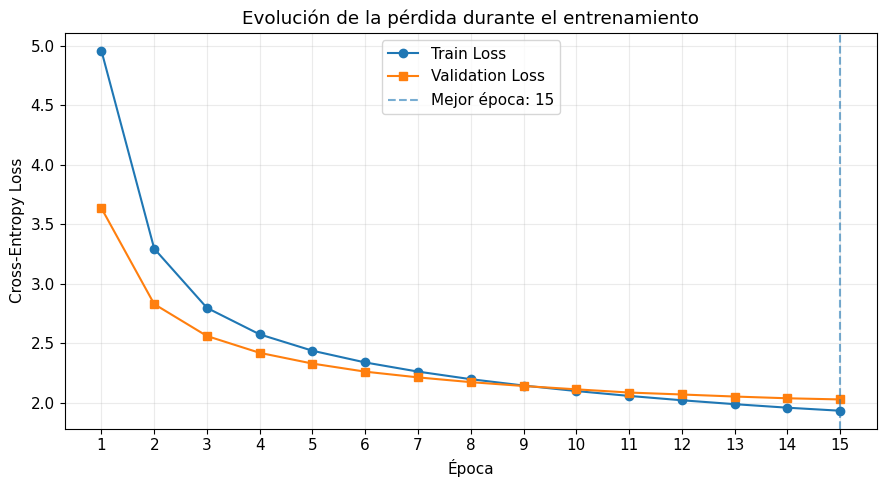

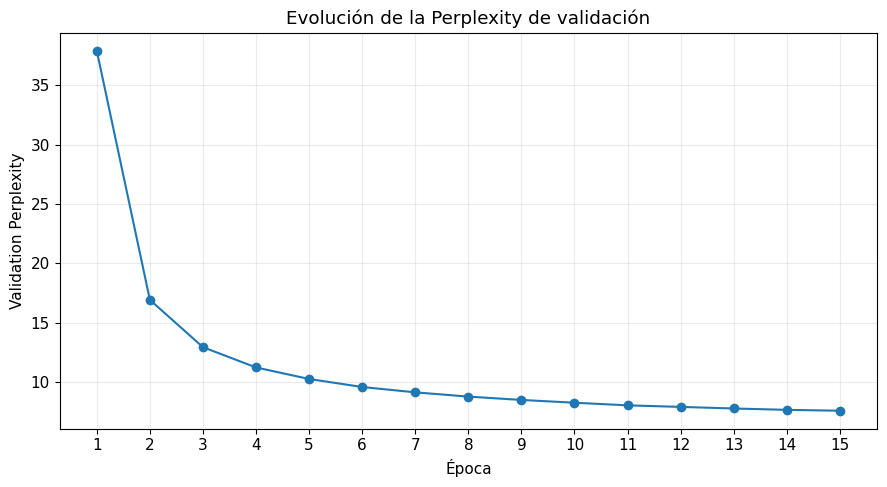

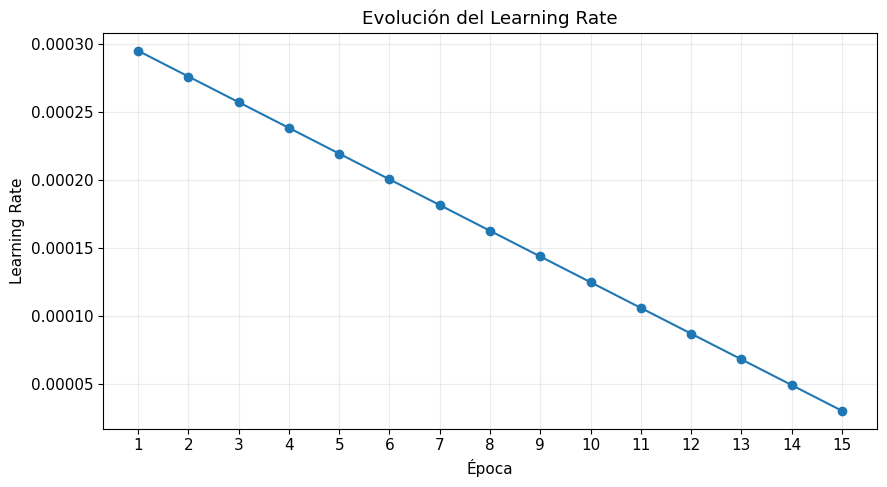


GRÁFICOS GENERADOS CORRECTAMENTE
01_train_vs_validation_loss.png
02_validation_perplexity.png
03_learning_rate.png

Ruta:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/graficos/entrenamiento


In [ ]:
# ==================================================
# 10. GRÁFICOS FINALES DEL ENTRENAMIENTO
# ==================================================

import json
import pandas as pd
import matplotlib.pyplot as plt

GRAFICOS_DIR = BASE_DIR / "resultados" / "graficos" / "entrenamiento"
GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)

HISTORIAL_PATH = BASE_DIR / "resultados" / "historial_entrenamiento.json"

with open(HISTORIAL_PATH, "r", encoding="utf-8") as f:
    historial = json.load(f)

df = pd.DataFrame(historial)

# Mejor época según Validation Loss
mejor_idx = df["val_loss"].idxmin()
mejor = df.loc[mejor_idx]

print("Mejor época:", int(mejor["epoch"]))
print("Mejor Validation Loss:", mejor["val_loss"])

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25
})

# ==================================================
# GRÁFICA 1: TRAIN LOSS VS VALIDATION LOSS
# ==================================================

fig, ax = plt.subplots()

ax.plot(
    df["epoch"],
    df["train_loss"],
    marker="o",
    label="Train Loss"
)

ax.plot(
    df["epoch"],
    df["val_loss"],
    marker="s",
    label="Validation Loss"
)

ax.axvline(
    int(mejor["epoch"]),
    linestyle="--",
    alpha=0.6,
    label=f"Mejor época: {int(mejor['epoch'])}"
)

ax.set(
    title="Evolución de la pérdida durante el entrenamiento",
    xlabel="Época",
    ylabel="Cross-Entropy Loss"
)

ax.set_xticks(df["epoch"])
ax.legend()

fig.tight_layout()

fig.savefig(
    GRAFICOS_DIR / "01_train_vs_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ==================================================
# GRÁFICA 2: VALIDATION PERPLEXITY
# ==================================================

fig, ax = plt.subplots()

ax.plot(
    df["epoch"],
    df["val_perplexity"],
    marker="o"
)

ax.set(
    title="Evolución de la Perplexity de validación",
    xlabel="Época",
    ylabel="Validation Perplexity"
)

ax.set_xticks(df["epoch"])

fig.tight_layout()

fig.savefig(
    GRAFICOS_DIR / "02_validation_perplexity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ==================================================
# GRÁFICA 3: LEARNING RATE
# ==================================================

fig, ax = plt.subplots()

ax.plot(
    df["epoch"],
    df["learning_rate"],
    marker="o"
)

ax.set(
    title="Evolución del Learning Rate",
    xlabel="Época",
    ylabel="Learning Rate"
)

ax.set_xticks(df["epoch"])

fig.tight_layout()

fig.savefig(
    GRAFICOS_DIR / "03_learning_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\n" + "=" * 60)
print("GRÁFICOS GENERADOS CORRECTAMENTE")
print("=" * 60)

for archivo in sorted(GRAFICOS_DIR.glob("*.png")):
    print(archivo.name)

print("\nRuta:")
print(GRAFICOS_DIR)